# 🌦️ NOAA Weather Time Series Analysis
**Cohort Time Series Project**

This notebook walks through an end-to-end time series analysis workflow using NOAA weather observations:
1. **Date Parsing & Schema Standardization**: Converting raw text dates and tabular date fields into native Pandas `Timestamp` objects.
2. **Date Sequences & Datetime Indexing**: Generating regular calendar grids using `pd.date_range()` and unlocking date-based partial string slicing with `DatetimeIndex`.
3. **Resampling & Rolling Averages**: Computing weekly (`'W'`) and monthly (`'ME'`) resampled averages alongside continuous 30-day moving averages (`.rolling()`).
4. **Temporal Feature Extraction**: Isolating calendar components (`month`, `day_of_week`) to discover seasonal weather patterns.
5. **Visual Trend Analysis**: Plotting raw observations, moving average trendlines, and monthly resampled summary markers for complete visual interpretation.


---
## Step 1: Loading the Dataset & Parsing Dates (`pd.to_datetime`)

### Specific Task
Load the NOAA weather dataset, inspect its column structure, and parse the date fields into Pandas `Timestamp` objects using `pd.to_datetime()`.

### Intuitive Explanation
In raw datasets, dates are frequently stored as plain strings or partitioned across separate columns (`year`, `month`, `day`). By converting them into native Pandas `datetime64` representations, Pandas automatically understands chronological order, leap years, days of the week, and temporal arithmetic.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 1. Load the NOAA weather dataset (using portable relative path)
df = pd.read_csv("noaa - 5000.csv")

# 2. Parse the text date column directly into Pandas Timestamp objects
df['date'] = pd.to_datetime(df['date'])

# 3. Alternatively, combine separate year, month, and day columns into Timestamps
df['date_from_fields'] = pd.to_datetime(
    df[['year', 'mo', 'da']].rename(columns={'year': 'year', 'mo': 'month', 'da': 'day'})
)

print("Dataset Overview (First 5 Rows):")
print(df[['stn', 'wban', 'date', 'temp', 'dewp', 'prcp']].head())
print("\nDate Column Data Types:")
print(df[['date', 'date_from_fields']].dtypes)


Dataset Overview (First 5 Rows):
     stn   wban       date  temp  dewp  prcp
0  10020  99999 2025-07-04  42.1  38.5   0.0
1  10020  99999 2025-04-30   7.6   3.8   0.0
2  10020  99999 2025-04-19   2.7  -2.5   0.0
3  10020  99999 2025-04-20   4.2  -1.0   0.0
4  10020  99999 2025-03-05  14.4  10.0   0.0

Date Column Data Types:
date                datetime64[us]
date_from_fields    datetime64[us]
dtype: object


---
## Step 2: Creating Regular Date Sequences (`pd.date_range`) & Datetime Indexing

### Specific Task
Generate a continuous annual calendar with `pd.date_range()` and set a `DatetimeIndex` on the NOAA DataFrame for intuitive date-based slicing.

### Intuitive Explanation
Setting a `DatetimeIndex` turns your DataFrame into a true time series object. Once indexed by time, Pandas allows you to select slices of data intuitively using date strings (for example, passing `'2025-07'` returns all readings from July 2025, or passing `'2025-07-04':'2025-07-20'` returns that exact date range). 

The `pd.date_range()` function generates regular sequences of dates across daily (`'D'`), monthly (`'MS'`), or hourly (`'h'`) frequencies.


In [2]:
# 1. Generate a continuous regular date range (e.g., daily frequency for 2025)
date_sequence = pd.date_range(start='2025-01-01', end='2025-12-31', freq='D')
print("Sample of generated date range:")
print(date_sequence[:5])

# 2. Set the DatetimeIndex and sort chronologically
df_indexed = df.set_index('date').sort_index()

print("\nIndex Verification:")
print(f"Index Type: {type(df_indexed.index)}")
print(f"Date Span: {df_indexed.index.min().date()} to {df_indexed.index.max().date()}")

# 3. Perform date-based slicing using intuitive string matching
# Extracts all station observations occurring in July 2025
july_2025_data = df_indexed.loc['2025-07']
print(f"\nTotal records found in July 2025: {len(july_2025_data)}")
print(july_2025_data[['stn', 'temp', 'dewp']].head(3))

# Slicing a specific date window
summer_window = df_indexed.loc['2025-07-04':'2025-07-20']
print(f"\nTotal records between 2025-07-04 and 2025-07-20: {len(summer_window)}")
print(summer_window[['stn', 'temp', 'dewp']].head(3))


Sample of generated date range:
DatetimeIndex(['2025-01-01', '2025-01-02', '2025-01-03', '2025-01-04',
               '2025-01-05'],
              dtype='datetime64[us]', freq='D')

Index Verification:
Index Type: <class 'pandas.DatetimeIndex'>
Date Span: 2025-01-01 to 2025-08-28

Total records found in July 2025: 710
               stn  temp  dewp
date                          
2025-07-01  330270  62.9  49.0
2025-07-01  309670  69.0  62.2
2025-07-01  311230  58.8  44.4

Total records between 2025-07-04 and 2025-07-20: 400
               stn  temp  dewp
date                          
2025-07-04  488310  84.2  76.6
2025-07-04  420990  91.1  79.9
2025-07-04  287860  75.1  62.2


---
## Step 3: Resampling (`.resample()`) & Rolling Windows (`.rolling()`)

### Specific Task
Compute weekly and monthly resampled series, align daily temperatures onto a continuous grid, and calculate a 30-day moving average using `.rolling()`.

### Intuitive Explanation
- **Resampling (`.resample()`)**: Changes the temporal frequency of the data (e.g., aggregating daily readings into weekly `'W'` or monthly `'ME'` checkpoints).
- **Rolling Windows (`.rolling()`)**: Maintains the original time frequency while smoothing out high-frequency fluctuations across a moving window of days.


In [3]:
# 1. Compute daily average temperature across all weather stations
daily_avg_temp = df.groupby('date')['temp'].mean().sort_index()

# 2. Ensure a continuous daily date grid across the observation span
full_date_range = pd.date_range(start=daily_avg_temp.index.min(), end=daily_avg_temp.index.max(), freq='D')
daily_full = daily_avg_temp.reindex(full_date_range)

# 3. Compute weekly and monthly resampled series
weekly_avg = daily_full.resample('W').mean()
monthly_avg = daily_full.resample('ME').mean()

# 4. Calculate a 30-day moving average using .rolling()
rolling_30d = daily_full.rolling(window=30, min_periods=1).mean()

# 5. Combine into a clean DataFrame to view results
smoothed_df = pd.DataFrame({
    'daily_temp': daily_full,
    'rolling_30d_temp': rolling_30d
})

print("Daily Temperature & 30-Day Rolling Mean (First 10 Days):")
print(smoothed_df.head(10))

print("\nWeekly Resampled Averages (First 5 Weeks):")
print(weekly_avg.head())

print("\nMonthly Resampled Averages:")
print(monthly_avg)


Daily Temperature & 30-Day Rolling Mean (First 10 Days):


            daily_temp  rolling_30d_temp
2025-01-01   50.387500         50.387500
2025-01-02   45.115000         47.751250
2025-01-03   48.352632         47.951711
2025-01-04   43.564286         46.854854
2025-01-05   47.028571         46.889598
2025-01-06   42.575000         46.170498
2025-01-07   38.847619         45.124373
2025-01-08   42.275000         44.768201
2025-01-09   47.921053         45.118518
2025-01-10   50.200000         45.626666

Weekly Resampled Averages (First 5 Weeks):
2025-01-05    46.889598
2025-01-12    45.981455
2025-01-19    48.628614
2025-01-26    45.990683
2025-02-02    45.941464
Freq: W-SUN, Name: temp, dtype: float64

Monthly Resampled Averages:
2025-01-31    46.684575
2025-02-28    48.817544
2025-03-31    55.454227
2025-04-30    61.440186
2025-05-31    67.004482
2025-06-30    66.982261
2025-07-31    70.408240
2025-08-31    67.591186
Freq: ME, Name: temp, dtype: float64


---
## Step 4: Extracting Calendar Attributes & Seasonality Analysis

### Specific Task
Extract calendar properties (`month`, `month_name`, `day_of_week`, `day_name`) directly from the `DatetimeIndex` to evaluate monthly and weekly temperature patterns.

### Intuitive Explanation
A `DatetimeIndex` provides built-in accessor properties for calendar metadata. Grouping by these attributes enables quick discovery of seasonal heating/cooling cycles and verifies whether data collection varies across different days of the week.


In [4]:
# 1. Extract calendar features from the DatetimeIndex
df_indexed['month'] = df_indexed.index.month
df_indexed['month_name'] = df_indexed.index.month_name()
df_indexed['day_of_week'] = df_indexed.index.dayofweek
df_indexed['day_name'] = df_indexed.index.day_name()

# 2. Aggregate temperature by month to discover seasonal trends
monthly_summary = df_indexed.groupby(['month', 'month_name'])['temp'].agg(
    mean_temp='mean',
    min_temp='min',
    max_temp='max',
    observation_count='count'
).reset_index().sort_values('month')

print("Monthly Temperature Summary:")
print(monthly_summary.to_string(index=False))

# 3. Aggregate temperature by day of the week
dow_summary = df_indexed.groupby(['day_of_week', 'day_name'])['temp'].agg(
    mean_temp='mean',
    observation_count='count'
).reset_index().sort_values('day_of_week')

print("\nDay of Week Temperature Summary:")
print(dow_summary.to_string(index=False))


Monthly Temperature Summary:


 month month_name  mean_temp  min_temp  max_temp  observation_count
     1    January  45.653073     -57.2      93.4                667
     2   February  47.156707     -59.1     102.2                656
     3      March  54.819702     -83.0     102.2                604
     4      April  61.089535     -97.0     104.3                602
     5        May  66.567719    -105.3     104.0                570
     6       June  67.142985     -98.9     107.5                670
     7       July  70.449718    -102.1     102.4                710
     8     August  68.461036     -95.8     109.4                521

Day of Week Temperature Summary:
 day_of_week  day_name  mean_temp  observation_count
           0    Monday  61.977727                660
           1   Tuesday  59.780028                711
           2 Wednesday  60.724038                728
           3  Thursday  58.579714                700
           4    Friday  57.383106                805
           5  Saturday  61.177650  

---
## Step 5: Visualizing Time Series Trends (Daily, Rolling, and Resampled)

### Specific Task
Plot the raw daily temperature measurements, the smoothed 30-day rolling trend, and the monthly resampled mean summary markers on a single unified chart.

### Intuitive Explanation
Combining raw daily data with both rolling and resampled aggregations allows analysts to see:
1. **Raw daily variation** (translucent light blue) showing day-to-day volatility.
2. **Rolling mean** (solid blue curve) highlighting the continuous trendline.
3. **Monthly resampled mean** (red dashed markers) providing macro benchmark reference points for each month.


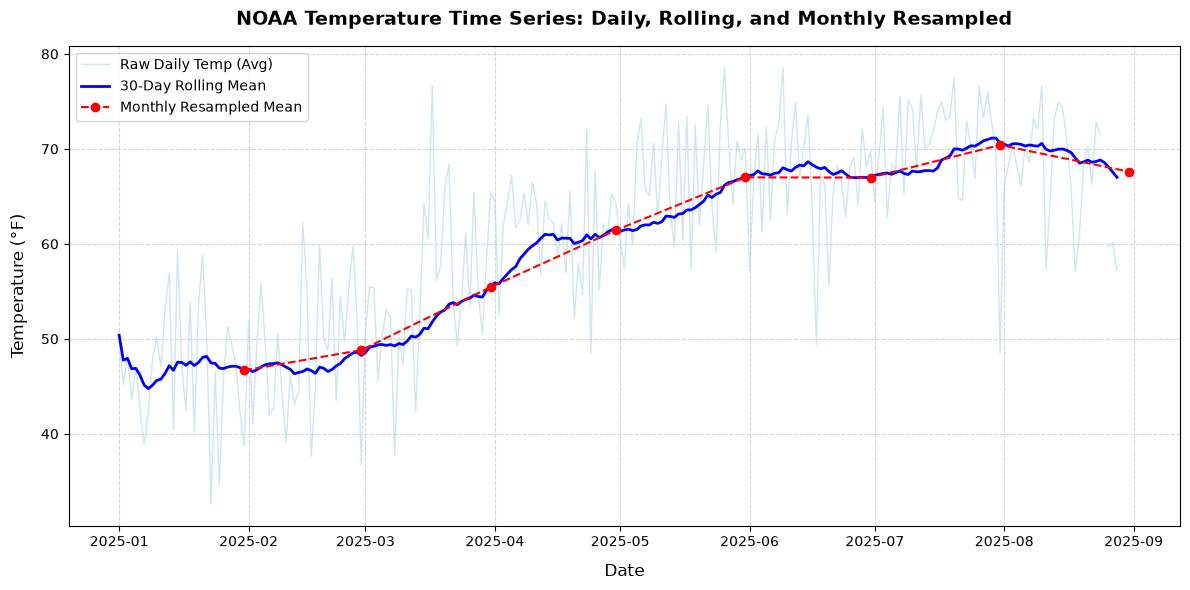

In [5]:
import matplotlib.pyplot as plt
import pandas as pd

# Fallback: ensure variables exist even if this cell is executed independently
if 'daily_full' not in globals() or 'rolling_30d' not in globals() or 'monthly_avg' not in globals():
    if 'df' not in globals():
        df = pd.read_csv("noaa - 5000.csv")
        df['date'] = pd.to_datetime(df['date'])
    daily_avg_temp = df.groupby('date')['temp'].mean().sort_index()
    daily_full = daily_avg_temp.reindex(pd.date_range(start=daily_avg_temp.index.min(), end=daily_avg_temp.index.max(), freq='D'))
    rolling_30d = daily_full.rolling(window=30, min_periods=1).mean()
    monthly_avg = daily_full.resample('ME').mean()

plt.figure(figsize=(12, 6), dpi=100)

# Plot raw daily data with high transparency
plt.plot(daily_full.index, daily_full, label='Raw Daily Temp (Avg)', color='lightblue', alpha=0.6, linewidth=1)

# Plot smoothed 30-day rolling trend
plt.plot(rolling_30d.index, rolling_30d, label='30-Day Rolling Mean', color='blue', linewidth=2)

# Plot monthly resampled summary points
plt.plot(monthly_avg.index, monthly_avg, label='Monthly Resampled Mean', color='red', marker='o', linestyle='--')

# Styling labels, title, and grid
plt.title('NOAA Temperature Time Series: Daily, Rolling, and Monthly Resampled', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Date', fontsize=12, labelpad=10)
plt.ylabel('Temperature (°F)', fontsize=12, labelpad=10)
plt.legend(loc='best')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()

# Display the plot
plt.show()


---
## 🎯 Key Takeaways & Project Summary

1. **Date Parsing**: Converting dates to `datetime64[ns]` ensures chronological integrity and eliminates date-format ambiguity.
2. **Datetime Indexing**: Slicing time series with strings like `.loc['2025-07']` simplifies temporal filtering without complex Boolean logic.
3. **Resampling vs. Rolling**: 
   - `.resample('W')` and `.resample('ME')` downsample the timeline to regular weekly and monthly summary checkpoints.
   - `.rolling(window=30)` smooths high-frequency noise while preserving daily timeline granularity.
4. **Seasonality**: Monthly grouping and visual trendlines clearly capture annual temperature cycles from winter lows through summer peaks.
